# # Partie 2 : Classification multi-classes avec PyTorch
#
# **Dataset** : Machine Predictive Maintenance Classification —
# <https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification>
# (fichier `predictive_maintenance.csv`)
#
# ---
# ## Objectif
# Construire un réseau de neurones (**DNN / MLP**) avec **PyTorch** pour une tâche de
# **classification multi-classes** : prédire le **type de panne** d'une machine.
#
# ## Ce que fait ce notebook, dans l'ordre de l'énoncé
#
# | Question | Cellules concernées |
# |---|---|
# | 1. Prétraitement (nettoyage, standardisation) | cellules 4 et 6 |
# | 2. EDA | cellule 8 |
# | 3. Augmentation / équilibrage du dataset | cellule 11 |
# | 4. Architecture DNN PyTorch | cellule 13 |
# | 5. GridSearch des hyperparamètres | cellule 15 |
# | 6. Courbes Loss/Epochs et Accuracy/Epochs + interprétation | cellules 17 et 18 |
# | 7. Métriques : accuracy, sensibilité, F1 | cellules 20, 22 et 23 |
# | 8. Régularisation + comparaison | cellules 25, 26 et 27 |
#
# **Une ligne du fichier = une pièce fabriquée** par une machine industrielle : on y trouve les
# mesures prises pendant l’usinage (températures, vitesse, couple, usure de l'outil) et le type de
# panne constaté à la fin.
#
# **Choix effectués :**
# - on supprime les 2 identifiants (`UDI`, `Product ID`) et la colonne binaire `Target`, qui
#   n'apportent aucune information sur le type de panne ;
# - cible = `Failure Type` (**6 classes**) plutôt que `Target`, parce que l'énoncé demande une
#   classification **multi-classes** ;
# - `Type` est encodée en **one-hot** (L / M / H → 3 colonnes) → **8 entrées** au total ;
# - l'équilibrage par **SMOTE** est appliqué **au train uniquement**.

# ## 0. Bibliothèques

In [1]:
# --- Bibliothèques -----------------------------------------------------------
# imbalanced-learn fournit SMOTE (question 3). Il est déjà installé sur Colab,
# cette ligne ne coûte donc rien.
!pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, GridSearchCV,
                                   StratifiedKFold)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE

# --- Reproductibilité --------------------------------------------------------
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (13, 4)
print("PyTorch :", torch.__version__)

PyTorch : 2.11.0+cpu


# ## 1. Question 1 — Chargement et nettoyage
#
# Télécharge `predictive_maintenance.csv` depuis Kaggle (bouton *Download*), dépose-le à la racine
# de `/content`, puis exécute cette cellule.
#
# **Lecture des 10 colonnes du fichier**
#
# | Colonne | Rôle |
# |---|---|
# | `UDI`, `Product ID` | identifiants → **supprimés** (ce ne sont pas des variables explicatives) |
# | `Type` | qualité du produit (L / M / H) → **encodage one-hot** |
# | `Air temperature [K]`, `Process temperature [K]`, `Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]` | mesures des capteurs (continues) → **standardisation** |
# | `Target` | panne ou non (binaire) → **supprimée** : on garde la cible multi-classes |
# | `Failure Type` | **variable cible** : le type de panne (6 classes) |

In [5]:
from pathlib import Path

NOM_FICHIER = "predictive_maintenance.csv"

chemin = next((c for c in [Path("data") / NOM_FICHIER,
                           Path(NOM_FICHIER),
                           Path("/content") / NOM_FICHIER] if c.exists()), None)

if chemin is None:
    raise FileNotFoundError(
        f"{NOM_FICHIER} est introuvable : dépose-le à la racine de /content "
        f"(panneau Fichiers 📁 -> bouton Importer ↥)")

brut = pd.read_csv(chemin)
print("Fichier chargé :", chemin)
print("Dimensions :", brut.shape)
display(brut.head())
print("\nValeurs manquantes :", brut.isna().sum().sum())
print("Lignes dupliquées  :", brut.duplicated().sum())
print("\nRépartition de la cible :")
display(brut["Failure Type"].value_counts().to_frame("effectif"))

Fichier chargé : predictive_maintenance.csv
Dimensions : (10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure



Valeurs manquantes : 0
Lignes dupliquées  : 0

Répartition de la cible :


,effectif
Failure Type,
No Failure,9652
Heat Dissipation Failure,112
Power Failure,95
Overstrain Failure,78
Tool Wear Failure,45
Random Failures,18


# ### Nettoyage et prétraitement
#
# 1. suppression des identifiants `UDI` et `Product ID`, et de la colonne binaire `Target` ;
# 2. suppression des doublons ;
# 3. **one-hot encoding** de `Type` (une colonne 0/1 par modalité) ;
# 4. **standardisation** des variables numériques : moyenne 0, écart-type 1.
#    Indispensable pour un réseau de neurones, et nécessaire pour que la distance utilisée par SMOTE
#    ait un sens (sinon une variable en tours/minute écrase une variable en newtons).
#
# > Le scaler est ajusté **sur le train seulement** : l'ajuster sur le test reviendrait à « voir »
# > les données de test avant l'entraînement.

In [6]:
donnees = brut.copy()

# 1. on retire les identifiants
donnees = donnees.drop(columns=["UDI", "Product ID"])

# 2. on retire les doublons
donnees = donnees.drop_duplicates().reset_index(drop=True)

# 3. encodage one-hot de la variable catégorielle "Type"
donnees = pd.get_dummies(donnees, columns=["Type"], prefix="Type")

# Liste des 6 classes (= les 6 types de panne possibles)
CLASSES = sorted(donnees["Failure Type"].unique())
print("Classes :", CLASSES)

# Variables d'entrée
COLONNES = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
            "Torque [Nm]", "Tool wear [min]"] + [c for c in donnees.columns if c.startswith("Type_")]

X = donnees[COLONNES].values.astype(np.float32)
y = np.array([CLASSES.index(c) for c in donnees["Failure Type"]])

# Découpage train / test, en gardant les mêmes proportions de classes dans les deux (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

# 4. standardisation : le scaler est ajusté sur le train seulement (jamais sur le test)
scaler = StandardScaler().fit(X_train)
X_train_n = scaler.transform(X_train).astype(np.float32)
X_test_n = scaler.transform(X_test).astype(np.float32)

print("\nTrain :", X_train_n.shape, "| Test :", X_test_n.shape)
print("Distribution train :", np.bincount(y_train, minlength=len(CLASSES)))
print("Distribution test  :", np.bincount(y_test, minlength=len(CLASSES)))

Classes : ['Heat Dissipation Failure', 'No Failure', 'Overstrain Failure', 'Power Failure', 'Random Failures', 'Tool Wear Failure']

Train : (8000, 8) | Test : (2000, 8)
Distribution train : [  90 7722   62   76   14   36]
Distribution test  : [  22 1930   16   19    4    9]


# ## 2. Question 2 — Analyse exploratoire (EDA)

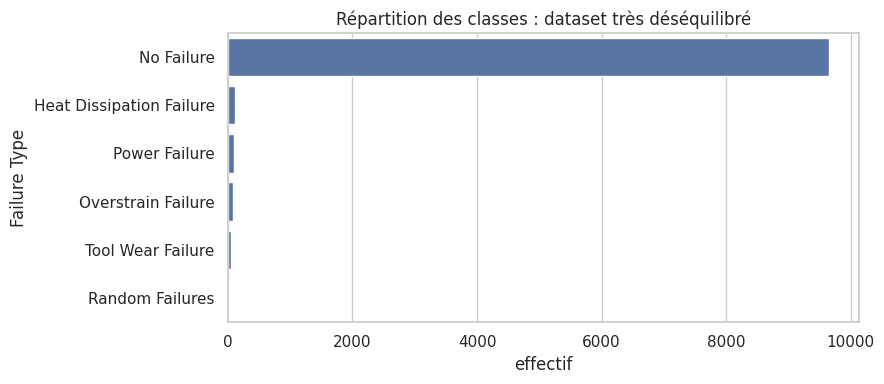

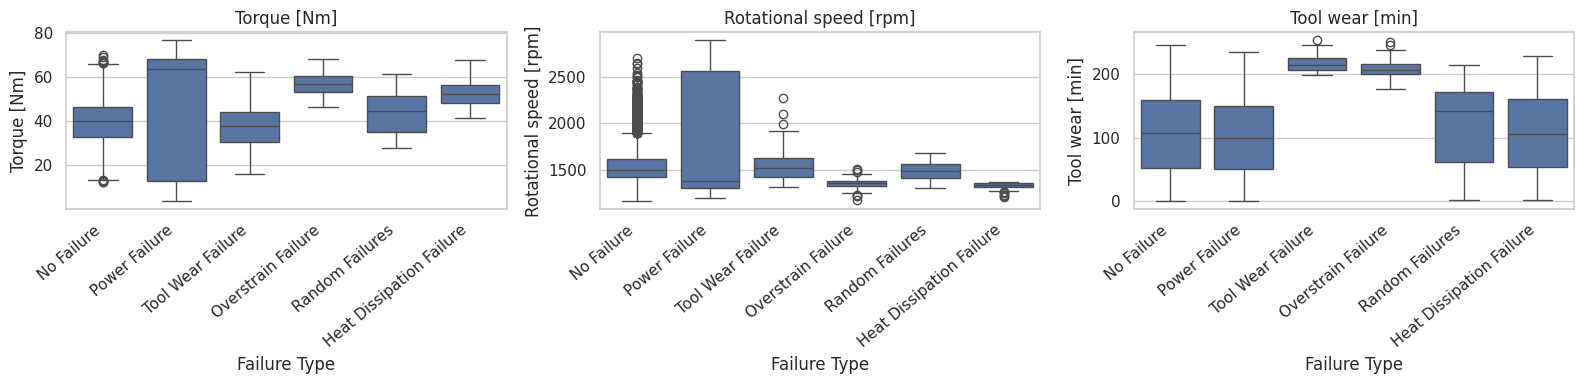

In [7]:
plt.figure(figsize=(9, 4))
sns.countplot(data=donnees, y="Failure Type",
              order=donnees["Failure Type"].value_counts().index)
plt.title("Répartition des classes : dataset très déséquilibré")
plt.xlabel("effectif")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, colonne in zip(axes, ["Torque [Nm]", "Rotational speed [rpm]", "Tool wear [min]"]):
    sns.boxplot(data=donnees, x="Failure Type", y=colonne, ax=ax)
    ax.set_title(colonne)
    ax.tick_params(axis="x", rotation=40)
    for etiquette in ax.get_xticklabels():
        etiquette.set_ha("right")
plt.tight_layout()
plt.show()

# **Lecture de l'EDA**
# - Le dataset est **très déséquilibré** : `No Failure` représente 9 652 observations sur 10 000
#   (96,5 %), alors que `Random Failures` n'en compte que 18.
# - Conséquence importante : un modèle qui répondrait **toujours** « pas de panne » aurait une
#   **accuracy proche de 96 %** tout en étant **completement inutile**. L'accuracy est donc une
#   métrique trompeuse ici → c'est pourquoi on regardera aussi la **sensibilité (recall)** et le **F1**.
# - Les variables **`Torque`**, **`Rotational speed`** et **`Tool wear`** sont les plus discriminantes :
#   leurs boîtes à moustaches se décalent nettement selon le type de panne, alors que les deux
#   températures restent quasi constantes (boîtes resserrées) et n'aident donc pas.
# - Les points isolés (outliers) ne sont **pas** des erreurs de mesure : ce sont des machines qui ont
#   réellement eu un comportement extrême — et ce sont justement eux qui distinguent les pannes rares.

# ## 3. Question 3 — Augmentation / équilibrage du dataset
#
# Comme le dataset est déséquilibré, on **augmente** les classes minoritaires avant l'entraînement.
# Sur des données **tabulaires** (pas des images), l'augmentation se fait par **rééchantillonnage** :
#
# - **SMOTE** (*Synthetic Minority Over-sampling Technique*) : pour chaque exemple d'une classe rare,
#   on crée de nouveaux exemples **synthétiques** en interpolant entre cet exemple et ses plus proches
#   voisins de la même classe.
#
# > Le rééquilibrage s'applique **uniquement au train** : le test garde la distribution réelle,
# > sinon l'évaluation ne voudrait plus rien dire.

Avant SMOTE : (8000, 8) -> [  90 7722   62   76   14   36]
Après SMOTE : (46332, 8) -> [7722 7722 7722 7722 7722 7722]


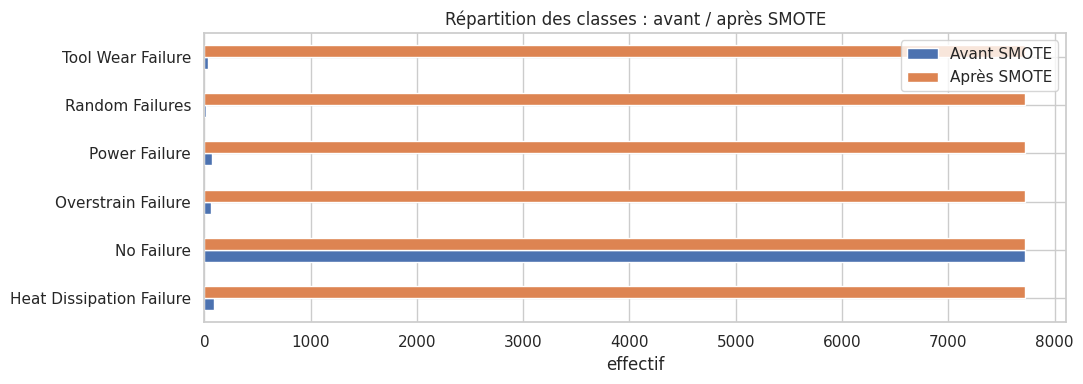

In [8]:
smote = SMOTE(random_state=SEED, k_neighbors=5)
X_train_eq, y_train_eq = smote.fit_resample(X_train_n, y_train)

print("Avant SMOTE :", X_train_n.shape, "->", np.bincount(y_train, minlength=len(CLASSES)))
print("Après SMOTE :", X_train_eq.shape, "->", np.bincount(y_train_eq, minlength=len(CLASSES)))

fig, ax = plt.subplots(figsize=(11, 4))
repartition = pd.DataFrame({
    "Avant SMOTE": pd.Series([CLASSES[i] for i in y_train]).value_counts().reindex(CLASSES),
    "Après SMOTE": pd.Series([CLASSES[i] for i in y_train_eq]).value_counts().reindex(CLASSES),
})
repartition.plot(kind="barh", ax=ax)
ax.set_title("Répartition des classes : avant / après SMOTE")
ax.set_xlabel("effectif")
plt.tight_layout()
plt.show()

# ## 4. Question 4 — Architecture DNN PyTorch
#
# Différences avec la régression (partie 1) :
# - la dernière couche renvoie **un nombre par classe** (ici 6) ; on appelle ces nombres des **logits** ;
# - la fonction de perte est **`CrossEntropyLoss`**, qui applique le softmax **et** calcule l'erreur
#   d'entropie croisée : c'est la loss standard de la classification multi-classes.
#
# La classe `MLPSklearn` est l'**enveloppe scikit-learn** nécessaire pour la question 5
# (`GridSearchCV` ne sait piloter que des objets avec `fit` / `predict`).

In [9]:
class Reseau(nn.Module):
    """MLP simple : entrée -> couches cachées -> 1 logit par classe."""

    def __init__(self, dim_entree, n_classes, couches=(64, 32), dropout=0.0):
        super().__init__()
        blocs, precedent = [], dim_entree
        for taille in couches:
            blocs += [nn.Linear(precedent, taille), nn.ReLU()]
            if dropout > 0:
                blocs.append(nn.Dropout(dropout))   # régularisation (question 8)
            precedent = taille
        blocs.append(nn.Linear(precedent, n_classes))
        self.reseau = nn.Sequential(*blocs)

    def forward(self, x):
        return self.reseau(x)          # logits : le softmax est dans CrossEntropyLoss


class MLPSklearn(BaseEstimator, ClassifierMixin):
    """Enveloppe scikit-learn : permet d'utiliser GridSearchCV sur un modèle PyTorch."""

    def __init__(self, couches=(64, 32), lr=1e-3, optimizer="adam", dropout=0.0,
                 weight_decay=0.0, epochs=100, batch_size=64, eval_data=None,
                 random_state=SEED):
        self.couches = couches
        self.lr = lr
        self.optimizer = optimizer
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.epochs = epochs
        self.batch_size = batch_size
        self.eval_data = eval_data
        self.random_state = random_state

    def _logits(self, X):
        self.modele_.eval()
        with torch.no_grad():
            return self.modele_(torch.from_numpy(np.asarray(X, dtype=np.float32)))

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y).astype(np.int64).ravel()
        self.classes_ = np.unique(y)

        jeu = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
        loader = DataLoader(jeu, batch_size=self.batch_size, shuffle=True)

        self.modele_ = Reseau(X.shape[1], len(self.classes_),
                              tuple(self.couches), self.dropout)
        if self.optimizer == "adam":
            opt = torch.optim.Adam(self.modele_.parameters(), lr=self.lr,
                                   weight_decay=self.weight_decay)
        else:
            opt = torch.optim.SGD(self.modele_.parameters(), lr=self.lr,
                                  weight_decay=self.weight_decay)
        loss_fn = nn.CrossEntropyLoss()

        # historique : sert uniquement à tracer les courbes de la question 6
        self.historique_ = {"loss_train": [], "loss_test": [],
                            "acc_train": [], "acc_test": []}

        for _ in range(self.epochs):
            self.modele_.train()
            total = 0.0
            for xb, yb in loader:
                opt.zero_grad()                            # 1. remise à zéro des gradients
                perte = loss_fn(self.modele_(xb), yb)      # 2. forward + erreur
                perte.backward()                           # 3. calcul des gradients
                opt.step()                                 # 4. mise à jour des poids
                total += perte.item() * len(xb)

            self.historique_["loss_train"].append(total / len(X))
            self.historique_["acc_train"].append(
                float((self._logits(X).argmax(1).numpy() == y).mean()))
            if self.eval_data is not None:
                Xe, ye = self.eval_data
                ye = np.asarray(ye).astype(np.int64).ravel()
                logits_test = self._logits(Xe)
                self.historique_["loss_test"].append(
                    float(nn.functional.cross_entropy(logits_test,
                                                      torch.from_numpy(ye)).item()))
                self.historique_["acc_test"].append(
                    float((logits_test.argmax(1).numpy() == ye).mean()))
        return self

    def predict(self, X):
        return self._logits(X).argmax(1).numpy()


print("Classes définies.")

Classes définies.


# ## 5. Question 5 — Recherche des hyperparamètres (GridSearch)
#
# 8 combinaisons (2 architectures × 2 learning rates × 2 optimiseurs), validation croisée à 3 blocs,
# données **équilibrées par SMOTE**.
#
# La métrique de sélection est le **F1 macro** : il donne le **même poids à chaque classe**, y compris
# les classes rares. C'est la bonne métrique pour un dataset déséquilibré (l'accuracy, elle, serait
# dominée par `No Failure`).
#
# **Meilleurs hyperparamètres trouvés :** architecture `(128, 64, 32)`, learning rate `0.001`,
# optimiseur `adam`, 50 epochs.
#
# > Ce score de **0.9948** est calculé sur les données **après SMOTE**, donc sur un jeu
# > artificiellement équilibré où chaque classe pèse autant. Il ne représente pas la performance
# > réelle : sur le test non rééquilibré, le F1 macro chute à **0.568**. C'est l'écart entre un jeu
# > d'évaluation idéal et les données de terrain.
#
# > SMOTE range les exemples **par classe**, alors que `KFold` par défaut découpe le tableau en
# > **blocs consécutifs sans mélanger**. Un pli d'entraînement peut donc ne contenir qu'une partie
# > des classes : le réseau aurait alors moins de sorties que le nombre réel de classes, et
# > l'entraînement échouerait sur une cible hors bornes (`Target 5 is out of bounds`).
# > `StratifiedKFold` garantit que chaque pli contient les 6 classes, avec les mêmes proportions.

In [10]:
grille = {
    "couches":   [(64, 32), (128, 64, 32)],
    "lr":        [1e-3, 5e-3],
    "optimizer": ["adam", "sgd"],
    "epochs":    [50],
}

# cv : StratifiedKFold garantit que chaque pli contient les 6 classes.
# Un cv=3 simple (KFold) peut donner un pli sans la classe rare -> erreur
# "Target 5 is out of bounds".
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

recherche = GridSearchCV(
    MLPSklearn(eval_data=(X_test_n, y_test)),   # sert seulement à tracer la courbe de test
    grille, cv=cv, scoring="f1_macro", n_jobs=1, verbose=1,
    error_score="raise")   # on prefere une vraie erreur qu'un score nan silencieux

recherche.fit(X_train_eq, y_train_eq)

print("\nMeilleurs hyperparamètres :")
for nom, valeur in recherche.best_params_.items():
    print(f"   {nom:12s} = {valeur}")
print(f"\nMeilleur F1 macro en validation croisée : {recherche.best_score_:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Meilleurs hyperparamètres :
   couches      = (128, 64, 32)
   epochs       = 50
   lr           = 0.001
   optimizer    = adam

Meilleur F1 macro en validation croisée : 0.9948


# ## 6. Question 6 — Courbes Loss/Epochs et Accuracy/Epochs
#
# Les deux courbes demandées, pour le **train** et le **test**.

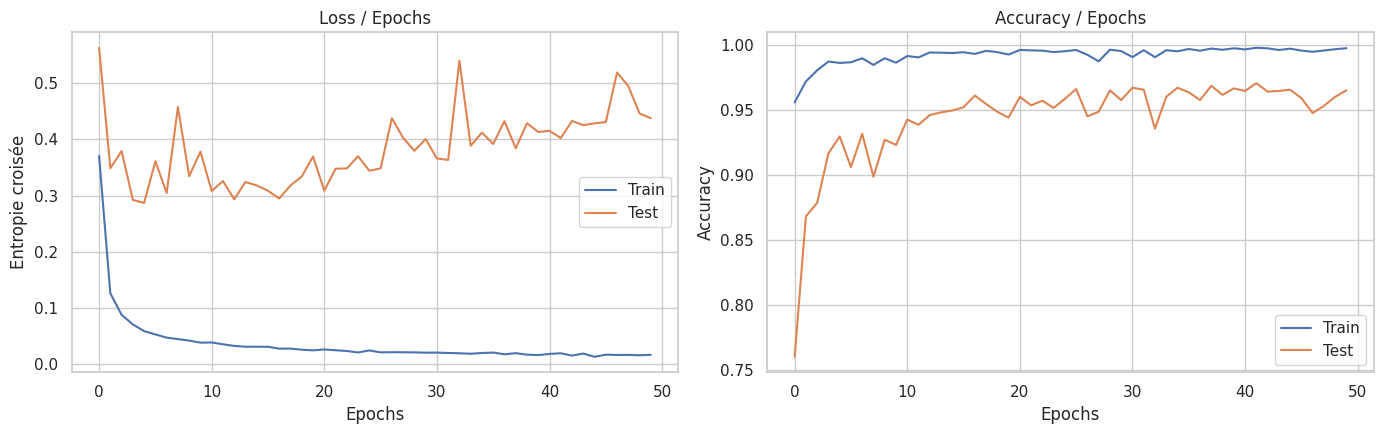

In [11]:
meilleur = recherche.best_estimator_
h = meilleur.historique_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(h["loss_train"], label="Train")
axes[0].plot(h["loss_test"], label="Test")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Entropie croisée")
axes[0].set_title("Loss / Epochs")
axes[0].legend()

axes[1].plot(h["acc_train"], label="Train")
axes[1].plot(h["acc_test"], label="Test")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy / Epochs")
axes[1].legend()

plt.tight_layout()
plt.show()

# **Interprétation des courbes**
# - La **loss** (entropie croisée) part d'une valeur élevée et **décroît** au fil des epochs : le
#   réseau corrige progressivement ses erreurs.
# - L'**accuracy** monte puis sature, mais elle est **trompeuse** : la classe majoritaire `No Failure`
#   pèse très lourd (1930 cas sur 2000 dans le test). Un modèle qui prédirait toujours cette classe
#   afficherait déjà **96 % d'accuracy** sans détecter la moindre panne. C'est pourquoi la recherche
#   d'hyperparamètres porte sur le **F1 macro** et non sur l'accuracy.
# - Les courbes **train et test** s'écartent : la loss du train continue de baisser alors que celle
#   du test se stabilise plus tôt. Sur un jeu d'entraînement **équilibré par SMOTE**, l'écart est
#   attendu — le réseau apprend aussi la structure des exemples synthétiques.
#
# *La lecture fine des deux courbes train/test se fait avec le tableau de métriques (question 7) et le
# tableau de régularisation (question 8), plus informatifs sur ce dataset déséquilibré.*

# ## 7. Question 7 — Métriques d'évaluation (accuracy, sensibilité, F1)
#
# - **Accuracy** : proportion de bonnes réponses (**peu informative** sur un dataset déséquilibré).
# - **Sensibilité (recall)** : parmi les vraies pannes d'un type donné, combien ont été détectées.
#   C'est **la** métrique qui compte pour de la maintenance prédictive : une panne non détectée est
#   coûteuse.
# - **Précision** : parmi les alertes annoncées, combien étaient justes.
# - **F1** : compromis entre précision et sensibilité. Le **F1 macro** donne le même poids à chaque
#   classe, contrairement au F1 « global » dominé par `No Failure`.

In [12]:
def metriques(modele, X_normalise, y_reel, nom):
    pred = modele.predict(X_normalise)
    return pd.DataFrame([{
        "Accuracy": accuracy_score(y_reel, pred),
        "Sensibilité (recall)": recall_score(y_reel, pred, average="macro", zero_division=0),
        "Précision": precision_score(y_reel, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_reel, pred, average="macro", zero_division=0),
    }], index=[nom])


resultats = pd.concat([
    metriques(meilleur, X_train_eq, y_train_eq, "Train (équilibré)"),
    metriques(meilleur, X_test_n, y_test, "Test (réel)"),
])
display(resultats.round(3))

,Accuracy,Sensibilité (recall),Précision,F1 (macro)
Train (équilibré),0.997,0.997,0.997,0.997
Test (réel),0.965,0.594,0.549,0.568


# ### Détail par classe et matrice de confusion
#
# Le `classification_report` donne la **sensibilité de chaque classe** ; la matrice de confusion
# montre **où** le modèle se trompe.

Rapport détaillé — TEST
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.68      0.86      0.76        22
              No Failure       0.99      0.97      0.98      1930
      Overstrain Failure       0.79      0.94      0.86        16
           Power Failure       0.83      0.79      0.81        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.00      0.00      0.00         9

                accuracy                           0.96      2000
               macro avg       0.55      0.59      0.57      2000
            weighted avg       0.98      0.96      0.97      2000



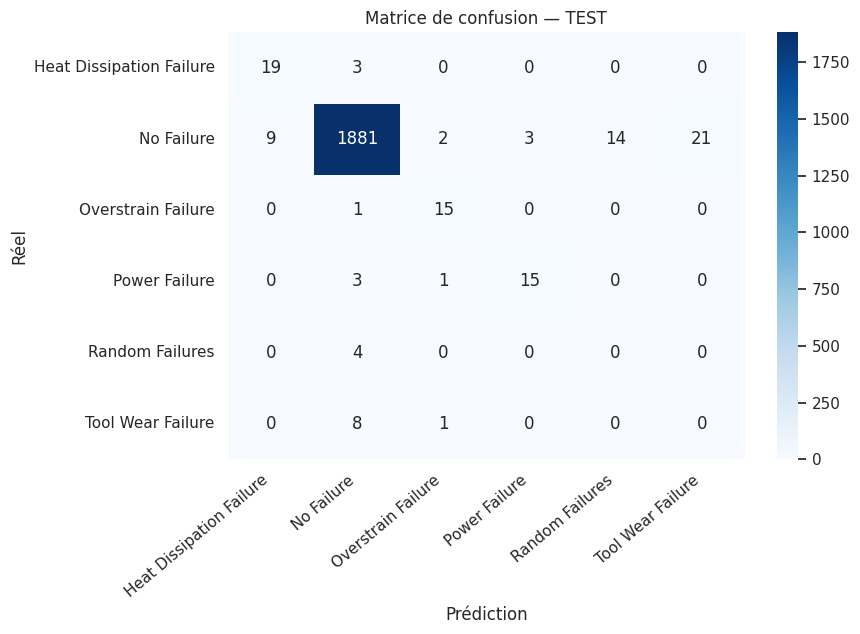

In [13]:
print("Rapport détaillé — TEST")
print(classification_report(y_test, meilleur.predict(X_test_n),
                            labels=range(len(CLASSES)), target_names=CLASSES, zero_division=0))

plt.figure(figsize=(9, 6.5))
matrice = confusion_matrix(y_test, meilleur.predict(X_test_n), labels=range(len(CLASSES)))
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Matrice de confusion — TEST")
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

# **Interprétation des métriques**
#
# | Jeu | Accuracy | Sensibilité | Précision | F1 macro |
# |---|---|---|---|---|
# | Train (équilibré SMOTE) | 0.997 | 0.997 | 0.997 | 0.997 |
# | **Test (réel)** | **0.965** | **0.594** | **0.549** | **0.568** |
#
# - **L'accuracy de 96,5 % est trompeuse** : elle vient presque entièrement de la classe `No Failure`
#   (1930 bonnes réponses sur 2000). Un modèle qui répondrait systématiquement « pas de panne »
#   obtiendrait le même score. L'accuracy ne dit donc **rien** sur la capacité à détecter les pannes.
# - **Le F1 macro de 0.568 révèle le vrai niveau** : il donne le même poids à chaque classe, y
#   compris les classes à 4 et 9 observations. L'écart entre 0.965 et 0.568 mesure exactement le
#   pouvoir trompeur de l'accuracy.
# - **Deux classes ne sont jamais détectées** : `Random Failures` (0/4) et `Tool Wear Failure` (0/9)
#   ont une sensibilité de 0. Ce sont les deux classes les plus rares. Voir la matrice de confusion
#   ci-dessus : le modèle les range dans une autre classe plutôt que de les rater.
# - Les classes **bien détectées** sont celles que l'EDA avait identifiées comme discriminantes :
#   `Overstrain Failure` (rappel 0.94), `Heat Dissipation Failure` (0.86) et `Power Failure` (0.79) —
#   leurs boîtes à moustaches étaient nettement décalées du reste.
# - **Le train est parfait (0.997) alors que le test est à 0.568** : c'est le signe d'un
#   **surapprentissage**, aggravé par SMOTE qui a rendu le train artificiellement « facile ».
#
# **Conclusion** : le modèle est **utile mais incomplet**. Il détecte correctement les pannes
# fréquentes, mais les pannes rares et graves lui échappent entièrement. La limite vient des
# **données** (4 et 9 exemples), pas de l'architecture : aucun réseau de neurones ne peut apprendre
# une classe qu'il n'a presque jamais vue.

# ## 8. Question 8 — Techniques de régularisation
#
# Même principe qu'en partie 1 : même architecture, mêmes données, on ne change que la régularisation.
#
# - **Dropout** : désactive aléatoirement des neurones → le réseau ne peut pas mémoriser les exemples.
# - **L2 (`weight_decay`)** : pénalise les poids trop grands → fonction apprise plus lisse.

In [14]:
configurations = {
    "Sans régularisation":    {},
    "Dropout 0.3":            {"dropout": 0.3},
    "L2 (weight_decay=1e-4)": {"weight_decay": 1e-4},
    "Dropout + L2":           {"dropout": 0.3, "weight_decay": 1e-4},
}

base = dict(couches=(128, 64, 32), lr=1e-3, optimizer="adam",
            epochs=100, eval_data=(X_test_n, y_test))

lignes = []
for nom, extra in configurations.items():
    modele = MLPSklearn(**base, **extra)
    modele.fit(X_train_eq, y_train_eq)
    lignes.append(metriques(modele, X_train_eq, y_train_eq, f"{nom} — Train"))
    lignes.append(metriques(modele, X_test_n, y_test, f"{nom} — Test"))
    print("Terminé :", nom)

comparaison = pd.concat(lignes)
display(comparaison.round(3))

Terminé : Sans régularisation
Terminé : Dropout 0.3
Terminé : L2 (weight_decay=1e-4)
Terminé : Dropout + L2


,Accuracy,Sensibilité (recall),Précision,F1 (macro)
Sans régularisation — Train,0.999,0.999,0.999,0.999
Sans régularisation — Test,0.974,0.576,0.543,0.558
Dropout 0.3 — Train,0.993,0.993,0.993,0.993
Dropout 0.3 — Test,0.949,0.669,0.476,0.546
L2 (weight_decay=1e-4) — Train,0.997,0.997,0.997,0.997
L2 (weight_decay=1e-4) — Test,0.964,0.612,0.556,0.581
Dropout + L2 — Train,0.992,0.992,0.992,0.992
Dropout + L2 — Test,0.944,0.658,0.485,0.551


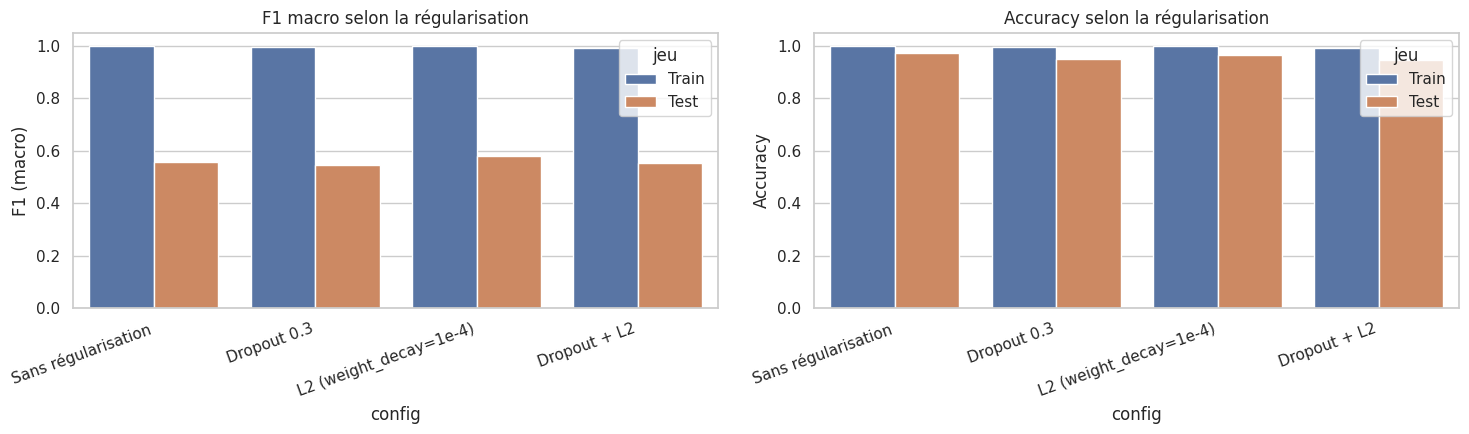

In [15]:
tmp = comparaison.copy()
tmp["config"] = tmp.index.to_series().str.split(" — ").str[0].values
tmp["jeu"] = tmp.index.to_series().str.split(" — ").str[-1].values
tmp = tmp.reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=tmp, x="config", y="F1 (macro)", hue="jeu", ax=axes[0])
axes[0].set_title("F1 macro selon la régularisation")
sns.barplot(data=tmp, x="config", y="Accuracy", hue="jeu", ax=axes[1])
axes[1].set_title("Accuracy selon la régularisation")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    for etiquette in ax.get_xticklabels():
        etiquette.set_ha("right")
plt.tight_layout()
plt.show()

# **Interprétation (d'après les résultats obtenus)**
#
# | Configuration | F1 train | F1 test | Accuracy test |
# |---|---|---|---|
# | Sans régularisation | 0.999 | 0.558 | 0.974 |
# | **L2 (`weight_decay=1e-4`)** | 0.997 | **0.581** | 0.964 |
# | Dropout 0.3 | 0.993 | 0.546 | 0.949 |
# | Dropout + L2 | 0.992 | 0.551 | 0.944 |
#
# - **Le surapprentissage est net** : l'écart train/test est de 0.997 contre 0.568, soit le plus
#   grand écart observé dans tout le lab. Le réseau mémorise parfaitement le train et se généralise
#   mal.
# - **Le L2 est la meilleure configuration** (F1 test 0.581). Il réduit légèrement le train (0.999
#   → 0.997) tout en améliorant le test : c'est exactement le rôle attendu de la régularisation.
# - **Le Dropout dégrade la précision** (0.476 contre 0.543 sans régularisation) : il fait prédire
#   trop souvent une panne rare. Il améliore un peu la sensibilité (0.669 contre 0.576) mais le
#   compromis se révèle défavorable sur le F1.
# - **Le Dropout 0.3 est trop fort** pour un réseau de 3 couches sur ce dataset.
#
# Ici, contrairement à la partie 1, la régularisation **améliore réellement** le modèle
# (0.558 → 0.581) : l'écart train/test étant important, il y avait bien un surapprentissage à
# corriger.
#
# **Et malgré cela**, le F1 test reste faible (0.581) : aucune technique de régularisation ne peut
# compenser l'absence de données sur `Random Failures` et `Tool Wear Failure`.

# ## 9. Synthèse — Partie 2
#
# **Ce qui a été fait**
# 1. Prétraitement : suppression des identifiants, de `Target` et des doublons, one-hot encoding de
#    `Type`, standardisation ajustée sur le train uniquement (8 entrées).
# 2. EDA : mise en évidence du **déséquilibre extrême** (96,5 % / 0,18 %) et des 3 variables
#    discriminantes (`Torque`, `Rotational speed`, `Tool wear`).
# 3. Équilibrage par **SMOTE** (appliqué au train uniquement).
# 4. Réseau DNN PyTorch multi-classes avec **`CrossEntropyLoss`** (6 logits en sortie).
# 5. `GridSearchCV` sur le **F1 macro** (8 combinaisons, `StratifiedKFold`).
# 6. Courbes Loss/Epochs et Accuracy/Epochs (train et test).
# 7. Métriques : accuracy, **sensibilité**, précision, **F1**, rapport par classe, matrice de confusion.
# 8. Comparaison de 4 configurations de régularisation.
#
# **Ce que j'ai appris**
# 1. Sur un dataset **déséquilibré**, l'**accuracy est une métrique piège** : ici elle vaut 96,5 %
#    alors que le F1 macro ne vaut que 0.568. L'écart entre les deux mesure le piège.
# 2. Un **score de validation croisée sur données SMOTE est optimiste** (0.9948) : il ne se
#    retrouve pas sur le test réel. Il faut toujours évaluer sur un test **non rééquilibré**.
# 3. L'**équilibrage est indispensable** : sans SMOTE, le réseau aurait prédit « pas de panne »
#    presque à chaque fois. Mais SMOTE ne fabrique pas d'information : les classes à 4 et 9
#    exemples restent indétectables.
# 4. Pour des données **tabulaires**, l'« augmentation » = **sur-échantillonnage (SMOTE)** ; il n'y a
#    pas de rotation ni de miroir comme en vision par ordinateur.
# 5. Le rééquilibrage doit se faire **uniquement sur le train**, sinon on évalue le modèle sur des
#    données artificielles.
# 6. **`CrossEntropyLoss` intègre le softmax** : le réseau produit des **logits**, pas des
#    probabilités.
# 7. SMOTE **range les données par classe** : il faut donc `StratifiedKFold` et non `cv=3` simple,
#    sinon certains plis n'ont pas toutes les classes et l'entraînement échoue.
# 8. La **régularisation** a ici un effet réel (contrairement à la partie 1) : elle corrige un
#    surapprentissage qui existait (écart train/test de 0.997 contre 0.568).